# Ejercicio 2: modelo YOLO propio – clasificación del tiempo atmosférico
Objetivo: entrenar un clasificador YOLO11n-cls capaz de reconocer 4 situaciones meteorológicas (**amanecer, lluvioso, nublado, soleado**) en fotografías, empezando con pocas épocas y aumentándolas después, analizar la pérdida y probar el modelo sobre imágenes y sobre un vídeo.

Al ser **clasificación** no se requieren cajas ni polígonos: la etiqueta es la carpeta de cada imagen, así que la anotación consiste en organizar `train/` y `val/` por clase.

In [1]:
import os, glob, collections, torch, ultralytics
HOME = os.getcwd(); DATA = f"{HOME}/dataset_tiempo"
print("ultralytics", ultralytics.__version__, "| dispositivo:", "cuda" if torch.cuda.is_available() else "cpu")
for split in ["train", "val"]:
    cont = {c: len(os.listdir(f"{DATA}/{split}/{c}")) for c in sorted(os.listdir(f"{DATA}/{split}"))}
    print(split, cont, "total =", sum(cont.values()))

ultralytics 8.4.156 | dispositivo: cpu
train {'amanecer': 300, 'lluvioso': 199, 'nublado': 249, 'soleado': 200} total = 948
val {'amanecer': 56, 'lluvioso': 16, 'nublado': 51, 'soleado': 53} total = 176


## 1. Estructura del dataset (train / val listas)

In [2]:
!find dataset_tiempo -maxdepth 2 -type d | sort
!ls dataset_tiempo/train/soleado | head -3

dataset_tiempo
dataset_tiempo/train
dataset_tiempo/train/amanecer
dataset_tiempo/train/lluvioso
dataset_tiempo/train/nublado
dataset_tiempo/train/soleado
dataset_tiempo/val
dataset_tiempo/val/amanecer
dataset_tiempo/val/lluvioso
dataset_tiempo/val/nublado
dataset_tiempo/val/soleado


shine1.jpg
shine10.jpg
shine100.jpg


## 2. Entrenamiento base con pocas épocas (3)

In [3]:
from ultralytics import YOLO
base = YOLO('yolo11n-cls.pt')
base.train(data=DATA, epochs=3, imgsz=224, batch=32, workers=2, device='cpu', name='base_e3', exist_ok=True, verbose=False, plots=True)

Ultralytics 8.4.156 🚀 Python-3.11.15 torch-2.14.0+cu130 CPU (Intel Xeon Processor @ 2.10GHz)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/aramber/ta04/ej2/dataset_tiempo, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=base_e3, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.

train: /home/aramber/ta04/ej2/dataset_tiempo/train... found 948 images in 4 classes ✅ 


val: /home/aramber/ta04/ej2/dataset_tiempo/val... found 176 images in 4 classes ✅ 


test: None...


...

               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 3/3 1.9it/s 1.6s

                   all      0.972          1


Speed: 0.0ms preprocess, 5.6ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to /home/aramber/ta04/ej2/runs/classify/base_e3


ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ff49f87d210>
curves: []
curves_results: []
fitness: 0.9857954680919647
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.9715909361839294, 'metrics/accuracy_top5': 1.0, 'fitness': 0.9857954680919647}
save_dir: PosixPath('/home/aramber/ta04/ej2/runs/classify/base_e3')
speed: {'preprocess': 0.0005126079465547016, 'inference': 5.6486171761207515, 'loss': 3.4863629397560466e-05, 'postprocess': 6.462500385334185e-05}
top1: 0.9715909361839294
top5: 1.0

## 3. Entrenamiento con más épocas (15)

In [4]:
modelo = YOLO('yolo11n-cls.pt')
modelo.train(data=DATA, epochs=15, imgsz=224, batch=32, workers=2, device='cpu', name='final_e15', exist_ok=True, verbose=False, plots=True, patience=50)

Ultralytics 8.4.156 🚀 Python-3.11.15 torch-2.14.0+cu130 CPU (Intel Xeon Processor @ 2.10GHz)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/aramber/ta04/ej2/dataset_tiempo, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final_e15, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=50, perspective=

train: /home/aramber/ta04/ej2/dataset_tiempo/train... found 948 images in 4 classes ✅ 


val: /home/aramber/ta04/ej2/dataset_tiempo/val... found 176 images in 4 classes ✅ 


test: None...


...

               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 3/3 1.9it/s 1.6s

                   all      0.983          1


Speed: 0.0ms preprocess, 5.7ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to /home/aramber/ta04/ej2/runs/classify/final_e15


ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ff48383ec10>
curves: []
curves_results: []
fitness: 0.9914772808551788
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.9829545617103577, 'metrics/accuracy_top5': 1.0, 'fitness': 0.9914772808551788}
save_dir: PosixPath('/home/aramber/ta04/ej2/runs/classify/final_e15')
speed: {'preprocess': 0.0005121534059071564, 'inference': 5.7397659886336525, 'loss': 2.4011373253332834e-05, 'postprocess': 6.921590573421615e-05}
top1: 0.9829545617103577
top5: 1.0

## 4. Análisis de la pérdida

 epoch  train/loss  val/loss  metrics/accuracy_top1
     1      0.8315    0.1324                 0.9602
     2      0.1981    0.0847                 0.9659
     3      0.1727    0.2254                 0.9318
     4      0.1647    0.1604                 0.9602
     5      0.1821    0.1488                 0.9773
     6      0.1532    0.1266                 0.9773
     7      0.1292    0.2541                 0.9489
     8      0.1083    0.0776                 0.9830
     9      0.1162    0.0827                 0.9773
    10      0.1109    0.0759                 0.9716
    11      0.0824    0.0635                 0.9773
    12      0.0530    0.0732                 0.9773
    13      0.0599    0.0657                 0.9773
    14      0.0584    0.0793                 0.9716
    15      0.0495    0.0968                 0.9659


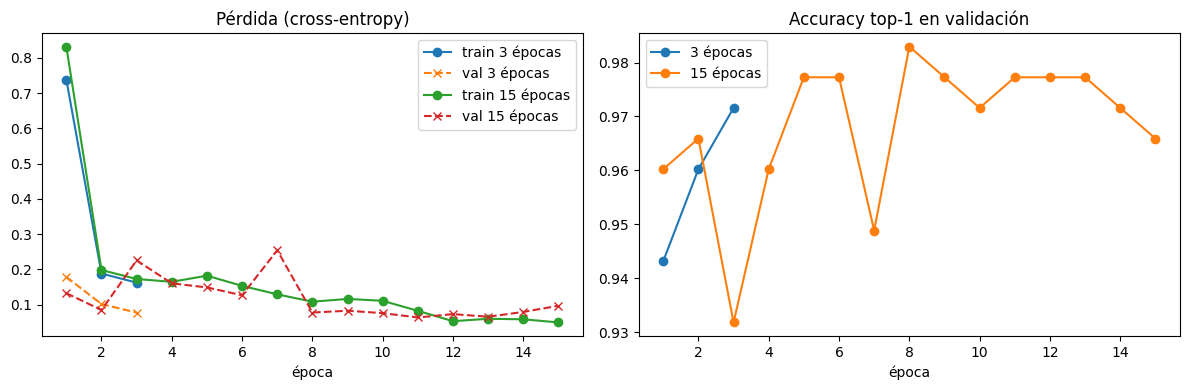

In [5]:
import pandas as pd, matplotlib.pyplot as plt
r3 = pd.read_csv('runs/classify/base_e3/results.csv'); r15 = pd.read_csv('runs/classify/final_e15/results.csv')
print(r15[['epoch','train/loss','val/loss','metrics/accuracy_top1']].round(4).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for r, n in [(r3, '3 épocas'), (r15, '15 épocas')]:
    ax[0].plot(r['epoch'], r['train/loss'], marker='o', label=f'train {n}'); ax[0].plot(r['epoch'], r['val/loss'], ls='--', marker='x', label=f'val {n}')
    ax[1].plot(r['epoch'], r['metrics/accuracy_top1'], marker='o', label=n)
ax[0].set_title('Pérdida (cross-entropy)'); ax[0].set_xlabel('época'); ax[0].legend()
ax[1].set_title('Accuracy top-1 en validación'); ax[1].set_xlabel('época'); ax[1].legend()
plt.tight_layout(); plt.savefig('perdidas.png', dpi=110); plt.show()

## 5. Evaluación final y matriz de confusión

In [6]:
best = YOLO('runs/classify/final_e15/weights/best.pt')
m = best.val(data=DATA, imgsz=224, device='cpu', verbose=False, plots=True)
print(f'top-1 = {m.top1:.3f} | top-5 = {m.top5:.3f}')
b3 = YOLO('runs/classify/base_e3/weights/best.pt').val(data=DATA, imgsz=224, device='cpu', verbose=False, plots=False)
print(f'Modelo base (3 épocas) top-1 = {b3.top1:.3f}')

Ultralytics 8.4.156 🚀 Python-3.11.15 torch-2.14.0+cu130 CPU (Intel Xeon Processor @ 2.10GHz)


YOLO11n-cls summary (fused): 47 layers, 1,531,148 parameters, 0 gradients, 3.2 GFLOPs


train: /home/aramber/ta04/ej2/dataset_tiempo/train... found 948 images in 4 classes ✅ 


val: /home/aramber/ta04/ej2/dataset_tiempo/val... found 176 images in 4 classes ✅ 


test: None...


...

               classes   top1_acc   top5_acc: 90% ━━━━━━━━━━╸─ 10/11 8.8it/s 1.1s<0.1s

               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 11/11 9.0it/s 1.2s

                   all      0.972          1


Speed: 0.0ms preprocess, 4.5ms inference, 0.0ms loss, 0.0ms postprocess per image


Modelo base (3 épocas) top-1 = 0.972


## 6. Prueba sobre imágenes de validación

In [7]:
import random, cv2
random.seed(7)
imgs = [random.choice(glob.glob(f'{DATA}/val/{c}/*')) for c in ['amanecer','lluvioso','nublado','soleado']]
for p in imgs:
    r = best(p, verbose=False)[0]
    print(f"{p.split('/')[-2]:9s} -> predicho: {r.names[r.probs.top1]:9s} ({r.probs.top1conf:.2f})")

amanecer  -> predicho: amanecer  (1.00)
lluvioso  -> predicho: lluvioso  (1.00)
nublado   -> predicho: nublado   (1.00)


soleado   -> predicho: soleado   (1.00)


## 7. Prueba en vídeo
Se compone un vídeo con fotogramas de validación de las cuatro clases (2 s por imagen) y se ejecuta el modelo fotograma a fotograma, superponiendo la clase predicha y su confianza.

In [8]:
random.seed(1)
sel = [f for c in ['soleado','nublado','lluvioso','amanecer'] for f in random.sample(glob.glob(f'{DATA}/val/{c}/*'), 3)]
W, H, fps = 640, 400, 10
vw = cv2.VideoWriter('entrada.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))
for f in sel:
    im = cv2.resize(cv2.imread(f), (W, H))
    for _ in range(2 * fps): vw.write(im)
vw.release()
out = cv2.VideoWriter('salida_predicciones.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))
cap = cv2.VideoCapture('entrada.mp4'); n = 0; muestras = []
while True:
    ok, fr = cap.read()
    if not ok: break
    r = best(fr, verbose=False)[0]; lab = f"{r.names[r.probs.top1]} {r.probs.top1conf:.2f}"
    cv2.rectangle(fr, (0, 0), (W, 42), (0, 0, 0), -1); cv2.putText(fr, lab, (12, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
    out.write(fr); n += 1
    if n % (2 * fps) == 10: muestras.append(fr.copy())
out.release()
cv2.imwrite('fotogramas_video.jpg', cv2.vconcat([cv2.hconcat(muestras[i:i+4]) for i in range(0, 12, 4)]))
print('fotogramas procesados:', n, '| vídeo generado: salida_predicciones.mp4')

fotogramas procesados: 240 | vídeo generado: salida_predicciones.mp4
